# Fair Aid QAOA: Benefit and Equity Weights under a Limited Aid Budget

**Qompute 2026 - Track 2 — Optimizing for People**

This experiment asks: when only three aid projects can be funded, how does changing the priority given to underserved communities change the optimal selection? How likely is QAOA to produce a feasible allocation close to the classical optimum?

We use teaching data for **six fictional projects with equal costs** to construct a six-qubit QAOA with a budget penalty. Each experiment is compared with exhaustive enumeration and random-selection baselines. This demonstrates the method; it provides neither an operational aid recommendation nor a claim of quantum advantage. All figures and findings come from the local files generated by the execution below.

## 1. Objective, Assumptions, and Reproduction

- Each project costs one budget unit, and exactly three projects must be selected. A knapsack problem with unequal costs requires an extended encoding.
- Base benefits, overlap losses, and equity points are synthetic scores. There are no observed population, health, or economic data.
- A, B, and C represent communities with established services; D, E, and F represent underserved communities. These labels define the fictional scenario.
- Equity points are a designer-selected priority proxy, not a fairness guarantee. The objective does not guarantee minimum coverage for every community.
- Computation uses an ideal statevector simulator, without hardware noise, a device topology, queueing, or an online account.

**Environment:** Install `requirements.txt` in the project's virtual environment, select its Jupyter kernel, and run the notebook from the beginning. Installation commands appear in this directory's [README](README.md). The notebook does not automatically install packages or download data. Inputs are in `data/`, outputs in `results/`, and figure source code in `plots.py`.

In [1]:
from pathlib import Path
import sys, csv, html, importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

working_directory = Path.cwd().resolve()
candidates = [working_directory, working_directory / "fair_aid",
              working_directory / "Track 2" / "fair_aid"]
PROJECT_DIR = next((p for p in candidates if (p / "allocation.py").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run from the repository root, Track 2, or fair_aid directory.")
sys.path.insert(0, str(PROJECT_DIR))

from allocation import load_problem
from run_experiments import run_suite
from plots import (read_rows, is_true, generate_figures, plot_tradeoff,
                   plot_probabilities, plot_penalty_sweep)

RESULTS_DIR = PROJECT_DIR / "results"
WEIGHTS = (0.0, 0.5, 1.0, 2.0)
DEPTHS = (1, 2)
SEEDS = (11, 29, 47)
PENALTY = 20.0
MAXITER = 160
SHOTS = 2048

def show_table(rows, columns, limit=24):
    # A small, portable HTML table; columns map source keys to display labels.
    header = "".join(f"<th>{html.escape(label)}</th>" for _, label in columns)
    body = []
    for row in list(rows)[:limit]:
        values = []
        for key, _ in columns:
            value = row.get(key, "")
            if isinstance(value, (float, np.floating)):
                value = f"{value:.4g}"
            values.append(f"<td>{html.escape(str(value))}</td>")
        body.append("<tr>" + "".join(values) + "</tr>")
    display(HTML("<table><thead><tr>" + header + "</tr></thead><tbody>"
                 + "".join(body) + "</tbody></table>"))

versions = {name: importlib.metadata.version(name)
            for name in ("qiskit", "numpy", "scipy", "matplotlib", "nbformat")}
print("Python:", sys.version.split()[0])
print("Packages:", versions)
print("Output directory:", RESULTS_DIR.relative_to(PROJECT_DIR).as_posix() + "/")

Python: 3.13.7
Packages: {'qiskit': '2.5.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'nbformat': '5.11.1'}
Output directory: results/


## 2. Inspect the Synthetic Data

The base benefit $b_i$ represents a project's value when implemented alone, and $e_i$ is its priority proxy. If two projects are selected together, $o_{ij}$ deducts the double counting caused by overlapping services. All scores are constructed, dimensionless teaching inputs.

We report benefit and equity scores separately so readers can see what changes when the objective weight changes. Optimal utility is not interpreted as a beneficiary count.

In [2]:
problem = load_problem()
projects = read_rows(PROJECT_DIR / "data" / "projects.csv")
show_table(projects, [("id", "Project"), ("name", "Project name"), ("unit_cost", "Cost"),
                      ("benefit", "Base benefit"), ("equity", "Equity points"),
                      ("underserved", "Underserved community flag")])
overlaps = read_rows(PROJECT_DIR / "data" / "overlaps.csv")
show_table(overlaps, [("first", "Project 1"), ("second", "Project 2"), ("penalty", "Overlap loss")])
assert problem.n == 6 and problem.k == 3
assert len(problem.enumerate(0.0, PENALTY)) == 64
print("Total allocations: 64; budget-feasible allocations:", sum(r["feasible"] for r in problem.enumerate(0.0, PENALTY)))

Project,Project name,Cost,Base benefit,Equity points,Underserved community flag
A,Central food hub,1,9,0,0
B,Established distribution center,1,8.5,0.5,0
C,Transit-accessible supply point,1,7,1,0
D,Mobile outreach team,1,6.5,2,1
E,Remote neighborhood delivery,1,6,3,1
F,Accessible home delivery,1,5.5,4,1


Project 1,Project 2,Overlap loss
A,B,1.2
A,C,1
A,D,0.4
A,E,0.2
A,F,0.3
B,C,0.8
B,D,0.3
B,E,0.5
B,F,0.2
C,D,0.2


Total allocations: 64; budget-feasible allocations: 20


## 3. From the Decision Objective to the Hamiltonian

Let $x_i\in\{0,1\}$ indicate whether project $i$ is selected, and let $w\geq0$ be the equity weight:

$$B(x)=\sum_i b_i x_i-\sum_{i<j}o_{ij}x_ix_j,\qquad
U_w(x)=B(x)+w\sum_i e_i x_i.$$

Maximizing utility is equivalent to minimizing the following cost, with the budget constraint included as a squared penalty:

$$C_{w,A}(x)=-U_w(x)+A\left(\sum_i x_i-3\right)^2.$$

Using $x_i^2=x_i$ gives the QUBO:

$$C=c+\sum_i a_i x_i+\sum_{i<j}Q_{ij}x_ix_j,$$
$$c=9A,\quad a_i=-(b_i+we_i)-5A,\quad Q_{ij}=o_{ij}+2A.$$

Substituting $x_i=(I-Z_i)/2$ gives $H_C$. We retain the identity term, so each computational basis state's energy must **equal its original cost**, with no additional offset. Project A maps to qubit 0, which is the rightmost bit in a Qiskit output bitstring.

### Why is the penalty sufficient?

Let $s_i=b_i+we_i$ and define

$$M(w)=\max_i\left\{s_i,\ \sum_{j\ne i}o_{ij}-s_i\right\}.$$

Removing one project from an over-selected allocation, or adding one to an under-selected allocation, increases the unpenalized cost by at most $M(w)$ while reducing the squared budget violation by at least one. Thus, when **$A>M(w)$**, every infeasible allocation has a lower-cost repair step, and every global ground state of the Hamiltonian is feasible. This bound is sufficient; it need not be the smallest effective penalty.

A feasible ground state does not imply that every measurement from a finite-depth QAOA is feasible. An excessive penalty can also make the optimizer prioritize feasibility over utility differences among feasible allocations. We therefore report both feasibility and optimality probabilities.

In [3]:
# Independent check from raw arrays, without using problem.cost()/metrics().
validation_rows = []
for weight in WEIGHTS:
    hamiltonian = problem.hamiltonian(weight, PENALTY)
    matrix = hamiltonian.to_matrix()
    direct_costs = []
    for state in range(1 << problem.n):
        bits = np.array([(state >> i) & 1 for i in range(problem.n)])
        benefit = sum(float(problem.benefit[i]) * bits[i] for i in range(problem.n))
        equity = sum(float(problem.equity[i]) * bits[i] for i in range(problem.n))
        overlap = sum(float(problem.overlap[i, j]) * bits[i] * bits[j]
                      for i in range(problem.n) for j in range(i + 1, problem.n))
        direct_costs.append(-benefit + overlap - weight * equity
                            + PENALTY * (sum(bits) - problem.k) ** 2)
    np.testing.assert_allclose(matrix, np.diag(direct_costs), atol=1e-10, rtol=0)
    bound = problem.penalty_bound(weight)
    assert PENALTY > bound
    validation_rows.append({"weight": weight, "bound": bound, "penalty": PENALTY,
                            "states_checked": len(direct_costs),
                            "max_error": float(np.max(np.abs(np.diag(matrix) - direct_costs)))})
show_table(validation_rows, [("weight", "w"), ("bound", "Sufficient bound M(w)"),
                            ("penalty", "A"), ("states_checked", "Basis states checked"),
                            ("max_error", "Maximum encoding error")])

w,Sufficient bound M(w),A,Basis states checked,Maximum encoding error
0,9,20,64,3.73e-14
0.5,9,20,64,3.73e-14
1,9.5,20,64,3.73e-14
2,13.5,20,64,3.73e-14


## 4. Run the QAOA Experiments

Each layer applies cost-Hamiltonian evolution followed by $X$ mixing, starting from $|+\rangle^{\otimes6}$. We use Qiskit's `QAOAAnsatz` and `StatevectorEstimator`, with COBYLA as the classical optimizer. Finally, `StatevectorSampler` draws 2,048 measurements.

Encoding checks retain the complete cost. For optimization, the implementation removes the identity term, which affects only global phase, and divides the remaining Pauli coefficients by their largest absolute value to normalize the optimization scale. Reported energies are restored to the original cost units. Parameter order, scale, and offset are saved in the raw results.

Four weights, two depths, and three random initializations give 24 optimization runs. Seeds are fixed and every run is retained. Each optimization has a budget of 160 objective calls. The optimizer may report nonconvergence upon reaching that budget; the actual results of those runs are also retained.

`summary.csv` records per-run metrics, `runs.json` records distributions, counts, and optimization histories, and `exact_solutions.csv` contains all feasible allocations. Running this cell again recomputes and overwrites the corresponding experiment artifacts in `results/`.

In [4]:
manifest = run_suite(RESULTS_DIR, weights=WEIGHTS, depths=DEPTHS, seeds=SEEDS,
                     penalty=PENALTY, maxiter=MAXITER, shots=SHOTS)
summary = read_rows(RESULTS_DIR / "summary.csv")
exact = read_rows(RESULTS_DIR / "exact_solutions.csv")
penalty_sweep = read_rows(RESULTS_DIR / "penalty_sweep.csv")
assert len(summary) == len(WEIGHTS) * len(DEPTHS) * len(SEEDS)
print(f"Completed {len(summary)} QAOA optimizations; results directory: {RESULTS_DIR.relative_to(PROJECT_DIR).as_posix()}/")

[01/24] mixer=x, weight=0, p=1, seed=11: P(feasible)=0.313, P(optimal)=0.016


[02/24] mixer=x, weight=0, p=1, seed=29: P(feasible)=0.286, P(optimal)=0.016


[03/24] mixer=x, weight=0, p=1, seed=47: P(feasible)=0.326, P(optimal)=0.017


[04/24] mixer=x, weight=0, p=2, seed=11: P(feasible)=0.344, P(optimal)=0.020


[05/24] mixer=x, weight=0, p=2, seed=29: P(feasible)=0.548, P(optimal)=0.020


...

[21/24] mixer=x, weight=2, p=1, seed=47: P(feasible)=0.521, P(optimal)=0.015


[22/24] mixer=x, weight=2, p=2, seed=11: P(feasible)=0.496, P(optimal)=0.012


[23/24] mixer=x, weight=2, p=2, seed=29: P(feasible)=0.648, P(optimal)=0.008


[24/24] mixer=x, weight=2, p=2, seed=47: P(feasible)=0.657, P(optimal)=0.072


Completed 24 QAOA optimizations; results directory: results/


## 5. Exact Classical Solutions: Weights Change Who Receives Aid

We enumerate all 64 binary allocations, of which $\binom63=20$ satisfy the budget. At this scale, enumeration is an inexpensive, reliable classical method and provides the reference for validating QAOA. The table lists every optimal allocation at each weight, including ties.

w,Optimal projects,Net benefit,Equity points,Underserved projects,Utility U
0.0,"A,B,D",22.1,2.5,1,22.1
0.5,"A,B,F",21.3,4.5,1,23.55
1.0,"A,E,F",19.4,7.0,2,26.4
2.0,"D,E,F",16.7,9.0,3,34.7


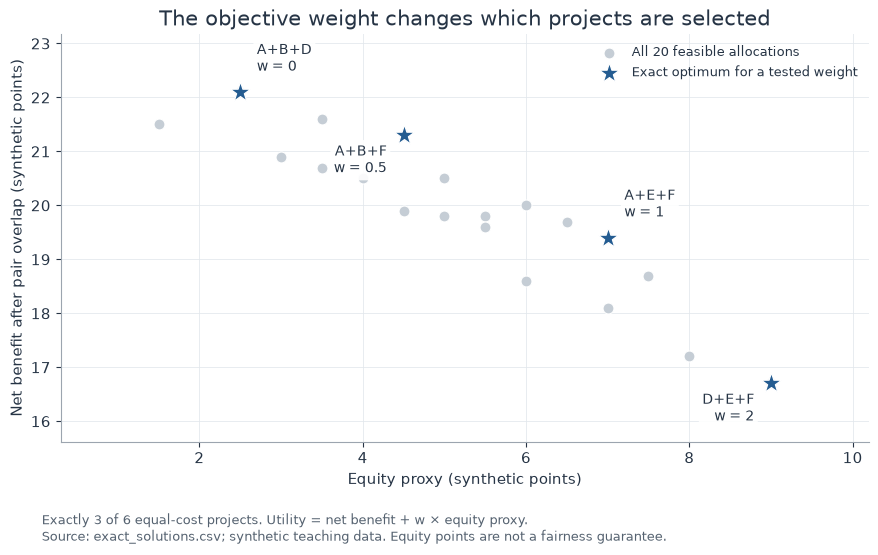

In [5]:
optimal_rows = [row for row in exact if is_true(row["is_optimal"])]
show_table(optimal_rows, [("weight", "w"), ("selected", "Optimal projects"),
                          ("net_benefit", "Net benefit"), ("equity_points", "Equity points"),
                          ("underserved_projects", "Underserved projects"), ("utility", "Utility U")])
plot_tradeoff(exact)
plt.show()

In [6]:
first_weight = min(WEIGHTS)
last_weight = max(WEIGHTS)
first_optima = [row for row in optimal_rows if float(row["weight"]) == first_weight]
last_optima = [row for row in optimal_rows if float(row["weight"]) == last_weight]
display(Markdown(
    f"**From this exact enumeration:** the optimal projects at w={first_weight:g} are "
    + " / ".join(row["selected"] for row in first_optima)
    + f"; at w={last_weight:g}, they are " + " / ".join(row["selected"] for row in last_optima)
    + ". This follows from a human-defined change in the objective weight; the quantum algorithm does not discover a fairness standard on its own."))

**From this exact enumeration:** the optimal projects at w=0 are A,B,D; at w=2, they are D,E,F. This follows from a human-defined change in the objective weight; the quantum algorithm does not discover a fairness standard on its own.

## 6. Measurement Probabilities: One Optimal Sample Is Not Enough

- **Feasible probability:** the probability that a measurement of the final state selects exactly three projects.
- **Optimal probability:** the probability of measuring a classically optimal feasible allocation. Its denominator includes every measurement outcome.
- **Conditional mean regret:** optimal utility minus the expected utility conditioned on feasibility, calculated from the final statevector. Lower is better.
- **Best-sampled regret:** the gap between the exact optimum and the best feasible utility among 2,048 samples. This can easily reach zero for a small instance with many samples and does not alone establish strong algorithmic performance.

Figure probabilities are calculated exactly from the final statevector; sampled frequencies in the table use finite shots. Means and minimum-to-maximum ranges summarize variation across three initializations and **are not confidence intervals**.

Random baselines also need a fair comparison. Uniform sampling over all 64 bitstrings is feasible with probability $20/64$, whereas a classical algorithm can sample directly from the 20 feasible combinations and guarantee feasibility. If a weight has a unique optimum, their optimal probabilities are $1/64$ and $1/20$, respectively. Ties are accounted for using the number of optimal allocations.

w,p,Mean feasible probability,Mean optimal probability,Sampled feasible rate,Sampled optimal rate,Conditional mean regret,Mean best-sampled regret
0,1,30.8%,1.6%,30.1%,1.4%,2.232,0
0,2,31.9%,1.4%,32.0%,1.5%,2.483,0
0.5,1,29.1%,1.5%,27.4%,1.5%,1.1,0
0.5,2,38.8%,1.9%,38.6%,1.9%,1.095,0
1,1,30.0%,1.5%,28.8%,1.5%,1.333,0
1,2,48.3%,2.5%,48.5%,2.6%,1.291,0
2,1,38.3%,1.6%,38.4%,1.7%,4.723,0
2,2,60.0%,3.1%,60.5%,3.0%,4.768,0


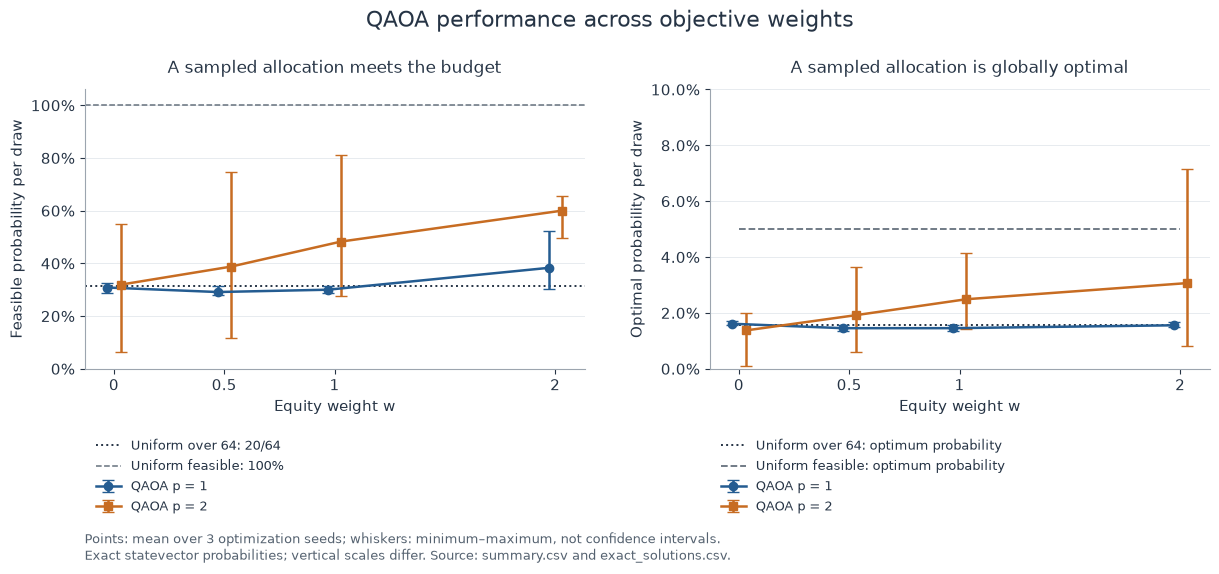

In [7]:
grouped = []
for weight in WEIGHTS:
    for depth in DEPTHS:
        rows = [r for r in summary if float(r["weight"]) == weight and int(r["depth"]) == depth]
        values = lambda key: np.array([float(r[key]) for r in rows])
        grouped.append({"weight": weight, "depth": depth,
                        "feasible": f"{values('feasible_probability').mean():.1%}",
                        "optimal": f"{values('optimal_probability').mean():.1%}",
                        "sample_feasible": f"{values('feasible_rate').mean():.1%}",
                        "sample_optimal": f"{values('optimal_rate').mean():.1%}",
                        "regret": float(values('conditional_regret').mean()),
                        "sample_regret": float(values('best_sampled_regret').mean())})
show_table(grouped, [("weight", "w"), ("depth", "p"), ("feasible", "Mean feasible probability"),
                     ("optimal", "Mean optimal probability"), ("sample_feasible", "Sampled feasible rate"),
                     ("sample_optimal", "Sampled optimal rate"), ("regret", "Conditional mean regret"),
                     ("sample_regret", "Mean best-sampled regret")])
plot_probabilities(summary, exact)
plt.show()

## 7. Penalty Checks and Computational Cost

The following check uses classical exhaustive enumeration to find global ground states at different penalties. It tests whether the encoding excludes infeasible allocations from the global optima. It does not establish optimizer convergence or the feasibility rate of measurements.

Circuit depth and two-qubit gate counts describe implementation cost. They depend on decomposition and compilation choices and are not direct estimates of device runtime. Wall-clock time on an ideal simulator is not evidence of quantum speedup.

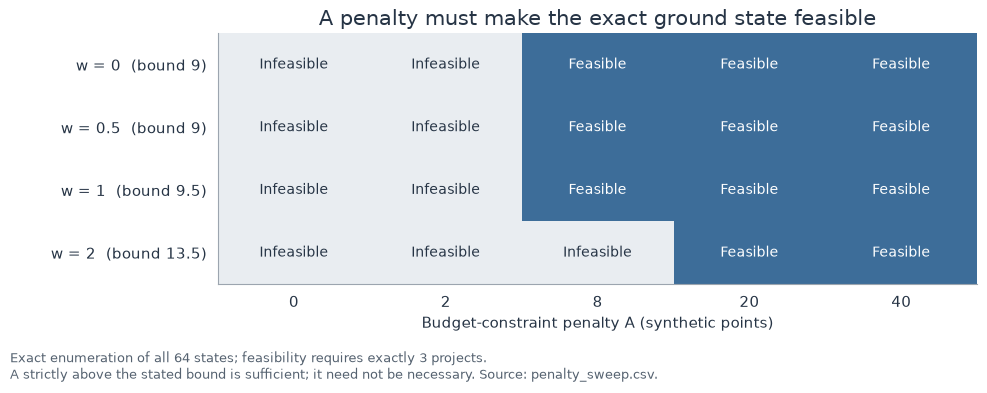

p,Circuit depth range,Two-qubit gate count range,Mean objective calls,Total optimization and sampling seconds,Reported convergence
1,30–30,30–30,64.67,2.363,11/12
2,50–50,60–60,151.8,6.451,5/12


Exported figures (PNG and SVG versions): allocation_tradeoff.png, qaoa_probabilities.png, penalty_feasibility.png


In [8]:
plot_penalty_sweep(penalty_sweep)
plt.show()
resource_rows = []
for depth in DEPTHS:
    rows = [r for r in summary if int(r["depth"]) == depth]
    resource_rows.append({
        "depth": depth,
        "circuit_depth": f"{min(int(r['circuit_depth']) for r in rows)}–{max(int(r['circuit_depth']) for r in rows)}",
        "two_qubit_gates": f"{min(int(r['two_qubit_gates']) for r in rows)}–{max(int(r['two_qubit_gates']) for r in rows)}",
        "mean_nfev": float(np.mean([float(r["nfev"]) for r in rows])),
        "seconds": float(sum(float(r["elapsed_seconds"]) for r in rows)),
        "success": f"{sum(is_true(r['optimizer_success']) for r in rows)}/{len(rows)}",
    })
show_table(resource_rows, [("depth", "p"), ("circuit_depth", "Circuit depth range"),
                           ("two_qubit_gates", "Two-qubit gate count range"), ("mean_nfev", "Mean objective calls"),
                           ("seconds", "Total optimization and sampling seconds"), ("success", "Reported convergence")])
figure_paths = generate_figures(RESULTS_DIR)
print("Exported figures (PNG and SVG versions):", ", ".join(path.name for path in figure_paths))

## 8. Derive Conclusions from the Results

The following text is generated from the CSV after execution. It does not assume that greater depth improves performance or interpret one exact-optimum sample as quantum advantage.

In [9]:
paired = []
if 1 in DEPTHS and 2 in DEPTHS:
    for weight in WEIGHTS:
        for seed in SEEDS:
            pair = {int(r["depth"]): r for r in summary
                    if float(r["weight"]) == weight and int(r["seed"]) == seed}
            paired.append(float(pair[2]["optimal_probability"]) - float(pair[1]["optimal_probability"]))
zero_regret_runs = sum(abs(float(row["best_sampled_regret"])) < 1e-9 for row in summary)
not_converged = sum(not is_true(row["optimizer_success"]) for row in summary)
messages = [
    f"- Of {len(summary)} runs, {zero_regret_runs} sampled an exact optimal feasible allocation within {SHOTS:,} shots.",
    f"- The optimizer did not report convergence in {not_converged} runs; all are retained in the comparison.",
]
if paired:
    messages.append(f"- Among {len(paired)} pairs matched by weight and random seed, p=2 had a higher optimal probability "
                    f"than p=1 in {sum(delta > 1e-10 for delta in paired)} pairs; the mean change was "
                    f"{100 * np.mean(paired):+.2f} percentage points. This comparison covers only these initializations and objective-call budgets.")
messages.append("- These findings apply only to the six synthetic projects and tested weights. They provide no evidence that this small QAOA outperforms classical enumeration.")
display(Markdown("\n".join(messages)))

- Of 24 runs, 24 sampled an exact optimal feasible allocation within 2,048 shots.
- The optimizer did not report convergence in 8 runs; all are retained in the comparison.
- Among 12 pairs matched by weight and random seed, p=2 had a higher optimal probability than p=1 in 6 pairs; the mean change was +0.69 percentage points. This comparison covers only these initializations and objective-call budgets.
- These findings apply only to the six synthetic projects and tested weights. They provide no evidence that this small QAOA outperforms classical enumeration.

## 9. Human Judgment and Further Work

**Who defines value?** Base benefits, overlap deductions, and equity points are policy choices. Beneficiaries, community representatives, and implementing organizations should help define them; an optimizer cannot replace their judgment.

**Who could be omitted?** A fixed candidate list excludes unlisted needs, equal costs obscure the costs of serving remote areas, and community labels plus a single weighted score cannot guarantee minimum service, individual fairness, or group equality. Further work can compare group coverage and benefits and add testable constraints, such as a minimum number of projects serving underserved communities.

**Who makes the final decision?** Present outputs as candidate allocations, identify excluded projects and sensitivity to weights, and let accountable organizations decide using community feedback. This example lacks the data quality and evaluation evidence required for real deployment.

**Algorithmic next steps:** Increase the number of starting points and the optimization budget to check robustness. Use a mixer that preserves the selected project count and compare it with uniform feasible sampling, greedy methods, or integer programming, then study noise and device connectivity. Before scaling up, specify which constraints require hard guarantees.

## 10. Files and Sources

- `data/projects.csv` and `data/overlaps.csv`: teaching data constructed for this project, not collected from a real aid system.
- `allocation.py`: cost, QUBO and Ising encodings, and enumeration.
- `run_experiments.py`: optimization, sampling, random baselines, and raw records.
- `plots.py`: editable Matplotlib functions; figure outputs are in `results/figures/`.
- [Track 2 requirements in the competition README](../../CHALLENGE.md#track-2-optimizing-for-people): constrained allocation, Qiskit, classical validation, and social impact.
- [Original Max-Cut introductory notebook](../Track2_challenge_2_tutorial.ipynb): QAOA teaching workflow, Benjamin Tirado / BasQ, CC BY 4.0.
- [IBM: QAOAAnsatz](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.QAOAAnsatz): cost operator, initial state, mixer operator, and `flatten`.
- [IBM: StatevectorEstimator](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator): local statevector expectation-value primitive.
- [IBM: StatevectorSampler](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler): measurement sampling and random seeds.

Tables and figures are based on the CSV files. Mathematical checks cover all 64 basis states at every weight. Correct encoding and reproducible execution validate this implementation; they do not demonstrate real aid outcomes or quantum speedup.